# scresonators: Fit Custom Resonator Data (Notebook)

This notebook loads your frequency and S-parameter data, runs a DCM (hanger) or Reflection fit, and plots the results.

- Inputs: `.npy` (complex) or CSV (`re,im` or `mag,phase_deg`)
- Units: set your input frequency units (converted to GHz internally)
- Methods: `dcm` (S21 hanger) or `reflection` (S11)


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add repo root to sys.path if this notebook is under examples/
try:
    CWD = Path.cwd()
    for cand in [CWD, *CWD.parents]:
        if (cand / 'src').exists():
            sys.path.insert(0, str(cand))
            break
except Exception:
    pass

# Try repo-local imports first, then installed package
try:
    from src.resonator import Resonator
    from src.fit_methods.dcm import DCM
    from src.fit_methods.reflection import ReflectionMode
except Exception:
    try:
        from scresonators.resonator import Resonator
        from scresonators.fit_methods.dcm import DCM
        from scresonators.fit_methods.reflection import ReflectionMode
    except Exception:
        try:
            from fit_resonator.resonator import Resonator
            from fit_resonator.fit_methods.dcm import DCM
            from fit_resonator.fit_methods.reflection import ReflectionMode
        except Exception as e:
            raise RuntimeError("Could not import scresonators. Run from repo root or install scresonators (or scresonators-fit).") from e


## Configure Inputs
Edit paths and options below to match your data. For the repo example files, the defaults work.


In [2]:
# Paths to your data
freq_path = Path('example2_f.npy')  # .npy or .csv
s21_path  = Path('example2_s21.npy')  # .npy or .csv

# Choose format of S21 if not complex npy
# Options: 'complex_npy', 'reim_csv', 'magphase_deg_csv'
s21_format = 'complex_npy'

# Frequency units of your input file; converted to GHz internally
# Options: 'GHz', 'Hz', 'MHz', 'kHz'
freq_units = 'GHz'

# Choose fitting method: 'dcm' for hanger (S21), 'reflection' for S11
method = 'dcm'

# Preprocessing: set False to skip electrical delay removal
remove_electrical_delay = True



## Load Data Helpers
Utilities to load arrays and parse S21 into complex form.


In [3]:
def load_array(path: Path) -> np.ndarray:
    path = Path(path)
    if path.suffix.lower() == '.npy':
        return np.load(path)
    # CSV/TXT fallback
    return np.genfromtxt(path, delimiter=',', dtype=float)

def parse_s21(data: np.ndarray, fmt: str) -> np.ndarray:
    fmt = fmt.lower()
    if fmt == 'complex_npy':
        if not np.iscomplexobj(data):
            raise ValueError('Expected complex dtype in npy for complex_npy format.')
        return data.astype(np.complex128)
    if fmt == 'reim_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('reim_csv expects 2 columns: re,im')
        return (data[:, 0] + 1j * data[:, 1]).astype(np.complex128)
    if fmt == 'magphase_deg_csv':
        if data.ndim == 1 or data.shape[1] < 2:
            raise ValueError('magphase_deg_csv expects 2 columns: mag,phase_deg')
        mag = data[:, 0]
        ph = np.deg2rad(data[:, 1])
        return (mag * np.exp(1j * ph)).astype(np.complex128)
    raise ValueError(f'Unknown s21-format: {fmt}')

def convert_freq_to_ghz(f: np.ndarray, units: str) -> np.ndarray:
    units = units.lower()
    scale = {'hz': 1e-9, 'khz': 1e-6, 'mhz': 1e-3, 'ghz': 1.0}
    if units not in scale:
        raise ValueError(f'Unsupported units: {units}')
    f_ghz = f * scale[units]
    return f_ghz.squeeze()


## Load and Inspect Data
Loads data using the settings above and shows basic info.


In [4]:
# Load frequency and S21
freqs_raw = load_array(freq_path).astype(float)
s21_raw = load_array(s21_path)

# Convert frequencies to GHz
freqs = convert_freq_to_ghz(freqs_raw, freq_units)

# Parse S21 according to selected format or auto-detect if possible
if s21_format == 'complex_npy' and s21_raw.ndim > 1:
    # If user selected complex_npy but provided 2-column CSV, try re,im as a convenience
    s21 = parse_s21(s21_raw, 'reim_csv')
else:
    s21 = parse_s21(s21_raw, s21_format)

print(f'freqs shape: {freqs.shape}, dtype: {freqs.dtype}')
print(f's21 shape:   {s21.shape}, dtype: {s21.dtype}, complex: {np.iscomplexobj(s21)}')
assert freqs.shape[0] == s21.shape[0], 'Frequency and S21 lengths must match'


freqs shape: (1001,), dtype: float64
s21 shape:   (1001,), dtype: complex128, complex: True


## Run Fit
Creates a `Resonator`, selects the fitting strategy, runs the fit, and prints parameters.


In [ ]:
res = Resonator()
res.load_data(fdata=freqs, sdata=s21)

if method.lower() == 'dcm':
    res.set_fitting_strategy(strategy=DCM())
elif method.lower() == 'reflection':
    res.set_fitting_strategy(strategy=ReflectionMode())
else:
    raise ValueError('method must be "dcm" or "reflection"')

# Control preprocessing
res.fitter.remove_elec_delay = bool(remove_electrical_delay)
res.fitter.preprocess_circle =True

params = res.fit(verbose=True)

def pval(name):  
    if name not in params:
        return None, None
    v = params[name].value
    se = params[name].stderr
    return v, se

print('Fit parameters:')
for key in ['f0', 'Q', 'Qc', 'Qi', 'phi']:
    v, se = pval(key)
    if v is None:
        continue
    se_str = f' ± {se:.3g}' if se is not None else ''
    print(f'  {key}: {v:.9g}{se_str}')


Q_guess: 9530.457142857143
initial delay guess: 2.3802402779886815e-08
phi (preprocessing): 1.6152750006496648
Q_guess: 10108.060606060606
[[Model]]
    Model(func)
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 78
    # data points      = 2002
    # variables        = 4
    chi-square         = 301.433597
    reduced chi-square = 0.15086767
    Akaike info crit   = -3782.49113
    Bayesian info crit = -3760.08352
    R-squared          = np.complex128(2.091403793900884+0.34444459214148554j)
[[Variables]]
    Q:    1060.79133 +/- 22.8877806 (2.16%) (init = 10108.06)
    Qc:   571.341978 +/- 9.66126766 (1.69%) (init = 5072.193)
    f0:   6.6688e+09 +/- 67821.3766 (0.00%) (init = 6.67132e+09)
    phi: -0.16663096 +/- 0.01690964 (10.15%) (init = 0)
[[Correlations]] (unreported correlations are < 0.100)
    C(f0, phi) = +0.7837
    C(Q, Qc)   = +0.7837
Fit parameters:
  f0: 6.66876495e+09 ± 6.78e+04
  Q: 1060.79133 ± 22.9
  Qc: 571.341978 ± 9.66
  Qi: -1276.60

## Plot Results
Magnitude (dB) vs frequency and a simple Smith chart overlay for data and fit.


##### Removing delay

In [ ]:
# import matplotlib.pyplot as plt
# delay=8.5e-8
# z = remove_delay(fd, sd_raw, delay)
# z0 = remove_delay(fd,sd_raw, 0)
# #plt.plot(z0.real, z0.imag, color='b')
# plt.plot(z.real, z.imag, color="r")

NameError: name 'remove_delay' is not defined

In [ ]:
# res.fitter.find_off_res_point(fd, z)

NameError: name 'fd' is not defined

In [24]:
# # Compute fitted curve and align plotting domains (normalized and raw)
# fd = res.fdata
# sd_raw = res.sdata



# # Determine delay from fit if available; else re-estimate
# delay = getattr(res.fitter, 'last_delay', None)
# delay=8.5e-8
# if delay is None:
#     delay = res.fitter.find_delay(fd, sd_raw)
#     print(f"Estimated delay : {delay}")

# # Remove delay 
# from src.utils import remove_delay
# z = remove_delay(fd, sd_raw, delay)

# #compute off-resonant point, then anchor to 1+0j (or chosen)
# old_orp = res.fitter.find_off_res_point(fd, z)
# anchor = res.fitter.off_res_point
# z_norm = anchor * z / old_orp

# # Model on grid in normalized domain
# method_obj = res.fitter.fit_method
# if hasattr(method_obj, 'fit_function'):
#     s_fit = method_obj.fit_function(fd, params)
# else:
#     kw = {}
#     for k in ['Q', 'Qc', 'f0', 'phi']:
#         if k in params:
#             kw[k] = params[k].value
#     s_fit = method_obj.func(fd, **kw)

# # Also bring model back to raw domain for apples-to-apples comparison
# s_fit_raw = (old_orp/anchor) * s_fit * np.exp(-2j*np.pi*delay*fd)

# fig, ax = plt.subplots(1, 2, figsize=(11, 4))
# # Left: raw domain magnitude
# ax[0].plot(fd, 20*np.log10(np.abs(sd_raw)), label='data (raw)')
# ax[0].plot(fd, 20*np.log10(np.abs(s_fit_raw)), label='fit (raw)', ls='--')
# ax[0].set_xlabel('f (GHz)')
# ax[0].set_ylabel('|S| (dB)')
# ax[0].legend()
# ax[0].grid(True, alpha=0.3)

# # Right: normalized Smith-like plot
# ax[1].plot(np.real(z_norm), np.imag(z_norm), label='data (norm)')
# ax[1].plot(np.real(s_fit), np.imag(s_fit), label='fit (norm)', ls='--')
# # Mark anchor (ORP maps here) and show theta0 if available
# ax[1].plot([np.real(anchor)], [np.imag(anchor)], 'go', label='anchor (ORP→anchor)')
# theta0_disp = getattr(res.fitter, 'theta_0', None)
# if theta0_disp is not None:
#     ax[1].text(0.02, 0.98, f'theta0={theta0_disp:.3f} rad', transform=ax[1].transAxes, va='top')
# ax[1].set_aspect('equal', adjustable='box')
# ax[1].set_xlabel('Re')
# ax[1].set_ylabel('Im')
# ax[1].legend()
# ax[1].grid(True, alpha=0.3)

# fig.suptitle('scresonators fit: raw and normalized views')
# plt.tight_layout()
# plt.show()


## Optional: Touchstone Input (skrf)
If you have a Touchstone file, you can load it directly if `scikit-rf` is installed.
Uncomment and adapt the cell below.


In [9]:
# from skrf import Network
# ts_file = 'path/to/your/file.s2p'  # or .s1p
# res2 = Resonator()
# res2.load_data_from_touchstone(ts_file)  # converts freq to GHz internally
# res2.set_fitting_strategy(strategy=DCM())  # or ReflectionMode() for S11
# params2 = res2.fit(verbose=True)
# print(params2)


# Protocol

 #### 1. preprocess_linear. 
Removes cable delay and normalizes phase/magnitude of S21 by linear fit of a specified number of endpoints.
#### 2. find_delay & remove_delay
#### 3. anchor_to_point

# Find f*cking delay

#### Current issues

1. fitter.find_delay function not working 

In [10]:
# Build a 2x2 view of the preprocessing pipeline
from src.utils import remove_delay, find_circle

fd = res.fdata
sd_raw = res.sdata

# Delay (from fit if available)

delay = getattr(res.fitter, 'last_delay', None)
print(delay)
#delay2 = 8.5e-8
if delay is None:
    delay = res.fitter.find_delay(fd, sd_raw)



1.9158080185493265e-08


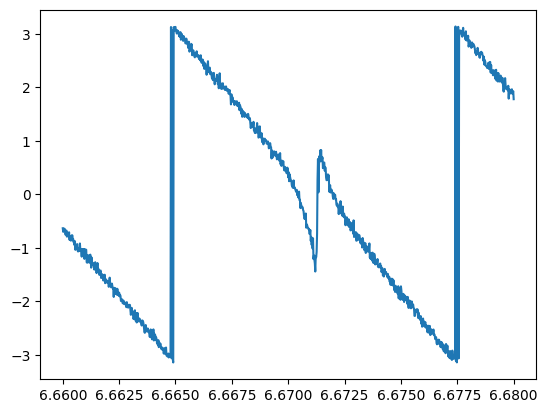

In [11]:
plt.plot(fd*1e-9, np.angle(sd_raw))

In [12]:
# dd = res.fitter.find_delay(fd, sd_raw)


# z3 = remove_delay(fd, sd_raw, dd)
# z2 = remove_delay(fd, sd_raw, delay2)
# xc, yc, r = find_circle(np.real(z2), np.imag(z2))


# plt.plot(np.angle(z2))
# plt.plot(np.angle(z3))

## Step-by-step Preprocessing Visuals
The following figure shows key steps of the pipeline: raw data, delay removal with circle fit, phase vs. arctan model, and normalized Smith overlay.


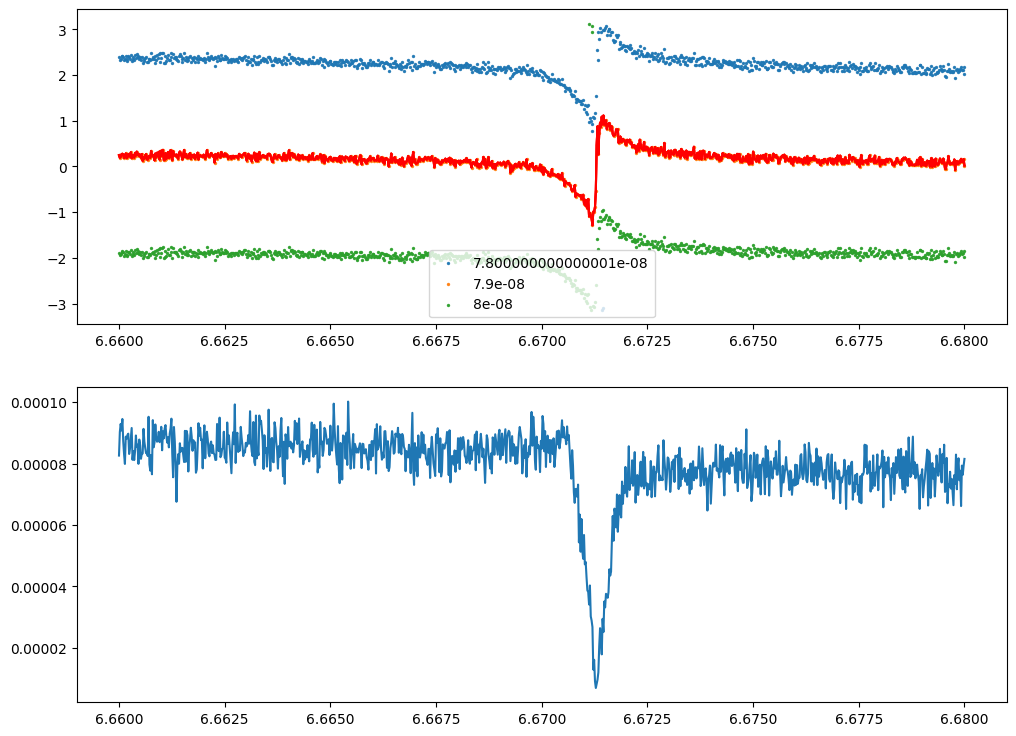

In [25]:
fig, axs = plt.subplots(2, figsize=(12, 9))

delay=79e-9
delays = delay + np.linspace(-1e-9,+1e-9,3)

for d in delays:
    axs[0].scatter(fd*1e-9 , np.angle(remove_delay(fd,sd_raw, d)), label=f"{d}", s=2,alpha=0.9)
    axs[0].plot(fd*1e-9, np.angle(remove_delay(fd,sd_raw, delay)), color='r')

axs[0].legend()
axs[1].plot(fd*1e-9, np.abs(sd_raw))

plt.show()


z2 = remove_delay(fd,sd_raw, delay)

7.9e-08


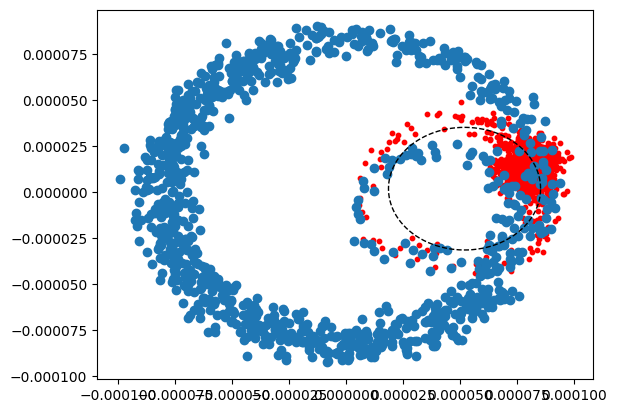

In [31]:
# Remove delay and circle fit
z2 = remove_delay(fd, sd_raw, delay)
print(delay)
xc, yc, r = find_circle(np.real(z2), np.imag(z2))

t = np.linspace(0, 2*np.pi, 512)
plt.scatter(z2.real, z2.imag, s=10, color='r')
plt.scatter(sd_raw.real, sd_raw.imag)
plt.plot(xc + r*np.cos(t), yc + r*np.sin(t), 'k--', lw=1, label='circle fit')



In [15]:
theta0 = res.fitter.theta_0
theta0

-0.54917671722661

phi (preprocessing): 0.5822819668992962


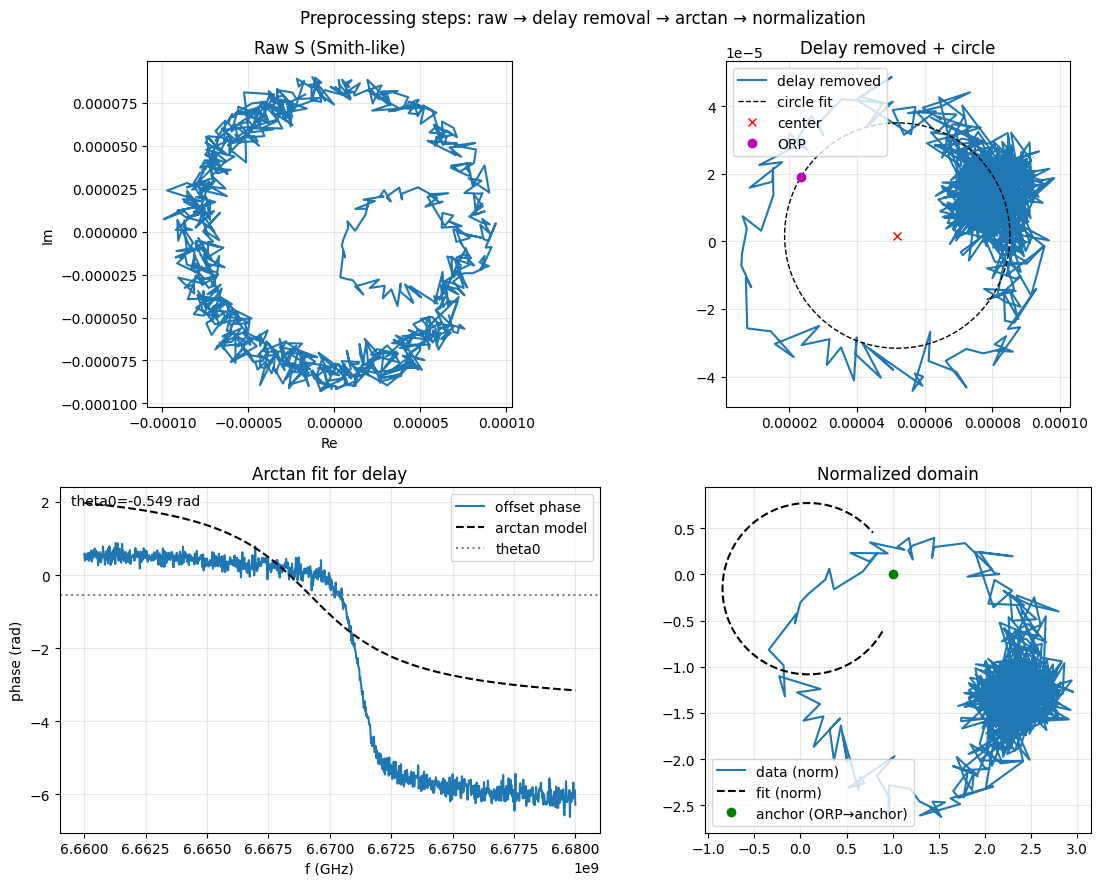

In [16]:


# Offset phase vs arctan model
theta0 = res.fitter.theta_0 if res.fitter.theta_0 is not None else 0.0
Ql_g  = res.fitter.Ql_guess if res.fitter.Ql_guess is not None else (params['Q'].value if 'Q' in params else 0.0)
fr_g  = res.fitter.fr_guess if res.fitter.fr_guess is not None else (params['f0'].value if 'f0' in params else fd[np.argmax(np.abs(np.gradient(z2, fd)))])

off_phase = np.unwrap(np.angle(z2 - (xc + 1j*yc)))
atan_phase = theta0 + 2*np.arctan(2*Ql_g*(1 - fd/fr_g))

# ORP and normalization
orp = res.fitter.find_off_res_point(fd, z2)
anchor = res.fitter.off_res_point
z2_norm = anchor * z2 / orp

# Model in normalized domain
method_obj = res.fitter.fit_method
if hasattr(method_obj, 'fit_function'):
    s_fit_n = method_obj.fit_function(fd, params)
else:
    kw = {}
    for k in ['Q', 'Qc', 'f0', 'phi']:
        if k in params:
            kw[k] = params[k].value
    s_fit_n = method_obj.func(fd, **kw)

# Figure
fig, axs = plt.subplots(2, 2, figsize=(12, 9))
# (1) Raw Smith
axs[0,0].plot(np.real(sd_raw), np.imag(sd_raw), label='raw')
axs[0,0].set_aspect('equal', adjustable='box')
axs[0,0].set_title('Raw S (Smith-like)')
axs[0,0].set_xlabel('Re')
axs[0,0].set_ylabel('Im')
axs[0,0].grid(True, alpha=0.3)
# (2) Delay-removed with circle fit
t = np.linspace(0, 2*np.pi, 512)
axs[0,1].plot(np.real(z2), np.imag(z2), label='delay removed')
axs[0,1].plot(xc + r*np.cos(t), yc + r*np.sin(t), 'k--', lw=1, label='circle fit')
axs[0,1].plot([xc], [yc], 'rx', label='center')
# Mark ORP on the delay-removed circle
axs[0,1].plot([np.real(orp)], [np.imag(orp)], 'mo', label='ORP')
axs[0,1].set_aspect('equal', adjustable='box')
axs[0,1].set_title('Delay removed + circle')
axs[0,1].legend()
axs[0,1].grid(True, alpha=0.3)
# (3) Offset phase vs arctan model
axs[1,0].plot(fd, off_phase, label='offset phase')
axs[1,0].plot(fd, atan_phase, 'k--', label='arctan model')
# Show theta0 reference
axs[1,0].axhline(theta0, color='gray', ls=':', label='theta0')
axs[1,0].text(0.02, 0.98, f'theta0={theta0:.3f} rad', transform=axs[1,0].transAxes, va='top')
axs[1,0].set_xlabel('f (GHz)')
axs[1,0].set_ylabel('phase (rad)')
axs[1,0].set_title('Arctan fit for delay')
axs[1,0].legend()
axs[1,0].grid(True, alpha=0.3)
# (4) Normalized Smith with model
axs[1,1].plot(np.real(z2_norm), np.imag(z2_norm), label='data (norm)')
axs[1,1].plot(np.real(s_fit_n), np.imag(s_fit_n), 'k--', label='fit (norm)')
axs[1,1].plot([np.real(anchor)], [np.imag(anchor)], 'go', label='anchor (ORP→anchor)')
axs[1,1].set_aspect('equal', adjustable='box')
axs[1,1].set_title('Normalized domain')
axs[1,1].legend()
axs[1,1].grid(True, alpha=0.3)

fig.suptitle('Preprocessing steps: raw → delay removal → arctan → normalization')
plt.tight_layout()
plt.show()
